# Tiamat — Baselines e pré-processamento (lance 40)

Neste notebook, só as partidas separadas para treino são utilizadas para ajustar modelos e avaliar desempenho por validação cruzada. Os conjuntos `val` e `test` permanecem reservados.

**Importante:** Este é um estudo preliminar; a comparação definitiva dos cinco algoritmos virá depois. Resultados obtidos aqui não autorizam afirmações causais sobre os atributos.

## 1. Bibliotecas e localização dos dados

O notebook procura o CSV nas pastas utilizadas durante a extração. Se estiver em outra pasta, altere `ARQUIVO_CSV`.

In [8]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

SEED = 210906
CANDIDATOS = [
    Path("data/piloto_final/lance_040.csv"),
    Path("data/piloto_corrigido/lance_040.csv"),
    Path("data/piloto/lance_040.csv"),
    Path("data/processed/lance_040.csv"),
    Path("lance_040(1).csv"),
    Path("lance_040.csv"),
    Path("/mnt/data/lance_040(1).csv"), # caminho de validação do notebook nesta sessão
]
ARQUIVO_CSV = next((p for p in CANDIDATOS if p.is_file()), None)
if ARQUIVO_CSV is None:
    raise FileNotFoundError("Não encontrei lance_040.csv. Ajuste CANDIDATOS para o caminho local.")
print("Arquivo:", ARQUIVO_CSV)
df = pd.read_csv(ARQUIVO_CSV)
print("Formato:", df.shape)
print("Divisões:\n", df["split"].value_counts().to_string())

Arquivo: data\piloto_final\lance_040.csv
Formato: (5156, 34)
Divisões:
 split
train    4612
test      274
val       270


## 2. Seleção explícita dos atributos e isolamento do treino

Na célula abaixo é realizado a seleção dos atributos. E a separação de um dataframe dos dados de treino.

In [9]:
ATRIBUTOS = [
    "rank_b", "rank_w", "komi", "handicap",
    "maior_grupo_b", "maior_grupo_w",
    "liberdades_maior_grupo_b", "liberdades_maior_grupo_w",
    "pedras_em_jogo_b", "pedras_em_jogo_w",
    "pedras_capturadas_por_b", "pedras_capturadas_por_w",
    "distancia_media_tengen_b", "distancia_media_tengen_w",
    "quantidade_grupos_b", "quantidade_grupos_w",
    "tamanho_medio_grupos_b", "tamanho_medio_grupos_w",
    "liberdades_medias_grupos_b", "liberdades_medias_grupos_w",
    "grupos_em_atari_b", "grupos_em_atari_w",
    "pedras_em_atari_b", "pedras_em_atari_w"
]
assert len(ATRIBUTOS) == 24
assert set(ATRIBUTOS).issubset(df.columns)
assert df["game_id"].is_unique, "Há partidas repetidas; revisar antes de seguir."
assert df["lance"].eq(40).all(), "O arquivo contém outro estágio!"
assert set(df["vencedor"].unique()) == {"B", "W"}

train = df.loc[df["split"].eq("train")].copy()
X = train[ATRIBUTOS].apply(pd.to_numeric, errors="raise")
y = train["vencedor"].map({"B": 0, "W": 1}).astype(int)
print(f"Treino: {len(train)} partidas, {X.shape[1]} atributos")
print("Classes (0 = B, 1 = W):", y.value_counts().sort_index().to_dict())
print("Ausentes no treino:\n", X.isna().sum()[X.isna().sum().gt(0)].to_string())
assert not np.isinf(X.to_numpy(dtype=float)).any(), "Existem valores infinitos."

Treino: 4612 partidas, 24 atributos
Classes (0 = B, 1 = W): {0: 2271, 1: 2341}
Ausentes no treino:
 komi        65
handicap     2


## 3. Estratégia de pré-processamento

Na célula abaixo será realizado uma imputação por mediana no conjunto de treinamento, nos atributos referentes a komi e a handicap. Dentro da pipeline de regressão logística, foi realizado foi feito uma padronização `StandardScaler`. E utilizado como no dummyclassifier a atribuição de probabilidade, com o corte para prever de a classe majoritária.

E em seguida é realizado a validação cruzada estratificada: 5 folds, com embaralhamento e semente fixa.


In [10]:
dummy = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", DummyClassifier(strategy="prior"))
])

logistica = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=3000, C=1.0, random_state=SEED))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
metricas = {
    "acuracia": "accuracy",
    "acuracia_balanceada": "balanced_accuracy",
    "f1_macro": "f1_macro",
    "roc_auc": "roc_auc",
    "neg_log_loss": "neg_log_loss"
}

## 4. Resultados dos baselines (validação cruzada)

Os mesmos folds são utilizados para comparar ambos os pipelines. A coluna `log_loss` é convertida para positiva (menor é melhor); as demais métricas são maiores quando o desempenho é melhor.

In [11]:
modelos = {"Dummy (prior)": dummy, "Regressão logística": logistica}
registros = []
for nome, pipeline in modelos.items():
    scores = cross_validate(pipeline, X, y, cv=cv, scoring=metricas,
                            n_jobs=-1, return_train_score=False)
    for i in range(cv.n_splits):
        registros.append({
            "modelo": nome, "fold": i + 1,
            "acuracia": scores["test_acuracia"][i],
            "acuracia_balanceada": scores["test_acuracia_balanceada"][i],
            "f1_macro": scores["test_f1_macro"][i],
            "roc_auc": scores["test_roc_auc"][i],
            "log_loss": -scores["test_neg_log_loss"][i],
        })
resultados_folds = pd.DataFrame(registros)
resumo = resultados_folds.groupby("modelo").agg({
    m: ["mean", "std"] for m in
    ["acuracia", "acuracia_balanceada", "f1_macro", "roc_auc", "log_loss"]
})
display(resumo.round(4))

acuracia         acuracia_balanceada         f1_macro  \
                        mean     std                mean     std     mean   
modelo                                                                      
Dummy (prior)         0.5076  0.0004              0.5000  0.0000   0.3367   
Regressão logística   0.5455  0.0161              0.5448  0.0163   0.5439   

                            roc_auc         log_loss          
                        std    mean     std     mean     std  
modelo                                                        
Dummy (prior)        0.0002  0.5000  0.0000   0.6930  0.0000  
Regressão logística  0.0166  0.5618  0.0211   0.6891  0.0046

### Visualização comparativa

As barras de erro representam o desvio padrão entre os cinco folds.

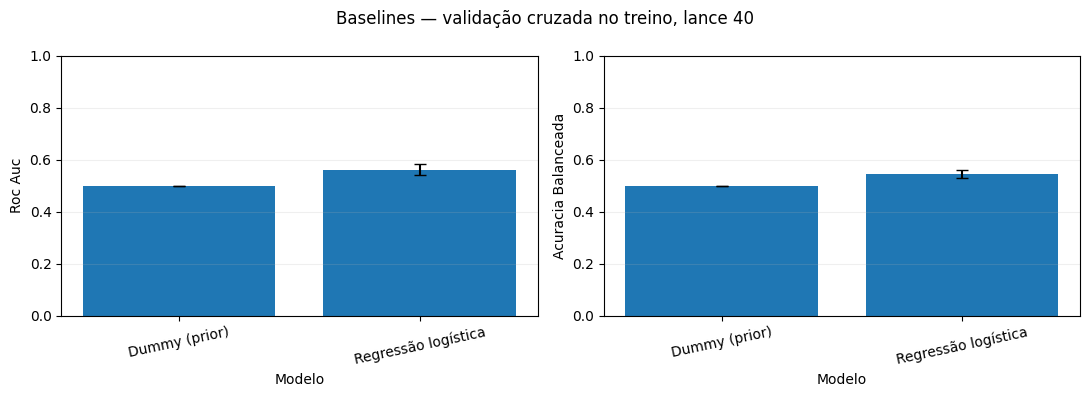

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metrica in zip(axes, ("roc_auc", "acuracia_balanceada")):
    tab = resultados_folds.groupby("modelo")[metrica].agg(["mean", "std"])
    ax.bar(tab.index, tab["mean"], yerr=tab["std"], capsize=4)
    ax.set_ylabel(metrica.replace("_", " ").title())
    ax.set_xlabel("Modelo")
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=12)
    ax.grid(axis="y", alpha=0.2)
fig.suptitle("Baselines — validação cruzada no treino, lance 40")
fig.tight_layout()
plt.show()

## 5. Matrizes de confusão com predições fora de cada fold

`cross_val_predict` gera uma previsão de cada observação usando um modelo que não foi ajustado com ela. Isso permite inspeção descritiva dos erros de classificação, sem tocar nas divisões oficiais de validação e teste.

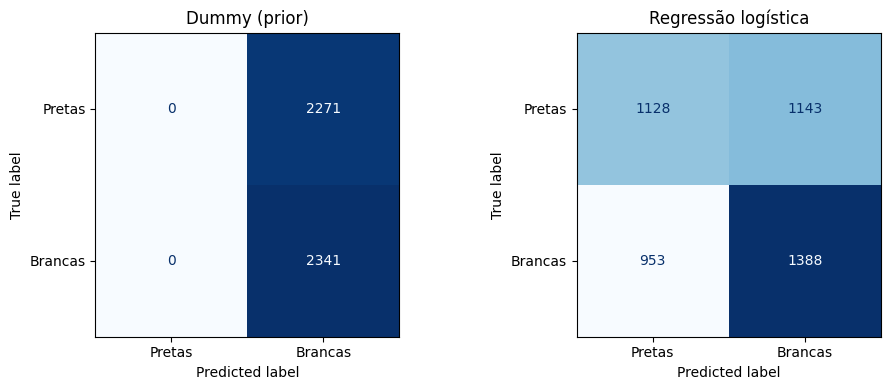

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (nome, pipeline) in zip(axes, modelos.items()):
    pred = cross_val_predict(pipeline, X, y, cv=cv, n_jobs=-1)
    ConfusionMatrixDisplay.from_predictions(
        y, pred, display_labels=["Pretas", "Brancas"],
        ax=ax, colorbar=False, cmap="Blues"
    )
    ax.set_title(nome)
fig.tight_layout()
plt.show()

## 6. Interpretações gerais

O Dummy apresenta uma acurácia próxima a 0,5, o que ocorre por ele está prevendo sempre o valor majoritária no conjunto de treino, o que leva a uma previsão ao acaso. A regressão logística apresenta uma melhoria significativa em relação ao Dummy nos cinco folds, em ambas as métricas, ROC-AUC e acuracia balanceada.

## 7. Conclusões provisórias e próximos passos

Os valores de baseline com o Dummy com acurácia média de 0,5076 e o de regressão logística com acurácia média de 0,5455, tem um resultado muito baixo. O proximo notebook `03_treinamento_otimizacao_tiamat.ipynb`, vai ser para otimização de com o Optuna. 

### Descrição do uso de IA neste trabalho

Foi utilizado de IA para a criação dos códigos do notebook, em que eles foram revisados pelo estudante, para a organização das seções e questionamentos orientadores de cada seção.

### Referências de apoio

- ATP-203, *Criaturas Lendárias do Reino de Lumi e onde encontrá-las*, seção Tiamat.
- [Scikit-learn — Pipelines](https://scikit-learn.org/stable/modules/compose.html)
- [Scikit-learn — Cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html)
- [Scikit-learn — Model evaluation](https://scikit-learn.org/stable/modules/model_evaluation.html)